In [1]:
import numpy as np
import pandas as pd
import sys, os
os.chdir('../')
from pathwaycca.prcca_x import solve_prcca_x, cv_prcca_pareto, pareto_select
from pathwaycca.significance_test import calculate_p_value_prcca_x

def make_lambda_grid(X, min_shift=-1, max_shift=1):
    # base = sqrt(p/n) snapped to the nearest power of 10; grid = {1, 5} x 10^(base+shift)
    n, p = X.shape
    raw_scale = np.sqrt(p / n)
    base_exponent = int(np.round(np.log10(raw_scale))) if raw_scale > 0 else 0
    grid = []
    for shift in range(min_shift, max_shift + 1):
        grid += [1 * 10**(base_exponent + shift), 5 * 10**(base_exponent + shift)]
    return np.sort(np.array(grid)), 10**base_exponent

In [2]:
input_path = "input_data/BRCA_subset/"
gene = "TP53"
X_input = pd.read_csv(f"{input_path}X_input_{gene}.csv", index_col=0)
Y_exp = pd.read_csv(f"{input_path}Full_Y_exp_subset.csv", index_col=0)
all_pathway_genes = pd.read_csv(f"input_data/pathway_db/msigdb_H_P53.csv")

In [3]:
pathway = "HALLMARK_P53_PATHWAY"
gene_list = all_pathway_genes.loc[all_pathway_genes["Pathway"] == pathway, "ENSG_ID"].tolist()
Y_input = Y_exp.loc[:,Y_exp.columns.intersection(gene_list)]
if Y_input.empty or Y_input.shape[1] < 2:
    print(f"Skipping {pathway} due to insufficient data")
X_input = X_input.iloc[:,:-1]
print(f"\nCurrent pathway: {pathway}")
print(f"Dimensions of X_input: {X_input.shape}")
print(f"Dimensions of Y_input: {Y_input.shape}")



Current pathway: HALLMARK_P53_PATHWAY
Dimensions of X_input: (705, 7)
Dimensions of Y_input: (705, 195)


In [4]:
n, p = X_input.shape
m = 4  # number of subtype dummy variables
gene_cols = list(range(0, p - m))  # Mut/CNA/Methyl columns
sub_cols = list(range(p - m, p))   # last m columns are subtype dummy columns

In [5]:
# Lambda grids (same as experiment script)
lambda_x1_grid, _ = make_lambda_grid(X_input.iloc[:, gene_cols], 0, 2)
lambda_x1_grid = lambda_x1_grid[1:-2]
lambda_y_grid, _ = make_lambda_grid(Y_input, 0, 2)
lambda_y_grid = lambda_y_grid[1:-2]

k = 3
cv_results = cv_prcca_pareto(X_input, Y_input,
    idx_x1=gene_cols,
    idx_x2=sub_cols,
    lambda_x1_grid=lambda_x1_grid,
    lambda_y_grid=lambda_y_grid,
    n_components=k,
    n_folds=3)
pareto = pareto_select(cv_results)
best_param = max(pareto, key=lambda r: (r["stability"] - r["gap"]))
print(best_param)
lambda_x1 = best_param["lambda_x1"]
lambda_x2 = best_param["lambda_x2"]
lambda_y = best_param["lambda_y"]

A_full, B, _, r = solve_prcca_x(X_input, Y_input,
    idx_x1=gene_cols,
    idx_x2=sub_cols,
    lambda_x1=lambda_x1,
    lambda_x2=lambda_x2,
    lambda_y=lambda_y,
    n_components=k)

{'lambda_x1': 5.0, 'lambda_x2': 5000.0, 'lambda_y': 50, 'test_corr': 0.37028121050387336, 'train_corr': 0.4224898572187858, 'gap': 0.14099690785541075, 'stability_A': 0.9960528317158784, 'stability_B': 0.8991075138499921, 'stability': 0.9475801727829353}


In [6]:
np.random.seed(42)
cache_dir = "interm/cache/PRCCA_X_random_pathway_results_cv/"
n_perm = 1001
observed_corr = r
p_val_res = calculate_p_value_prcca_x(X_input, Y_input,
                       Y_exp, gene_cols, sub_cols, observed_corr, n_perm=n_perm,
                       lambda_x1=lambda_x1, lambda_x2=lambda_x2, lambda_y=lambda_y, tune_lambda=False,
                       cache_base=cache_dir, file_name="test_TP53",
                       n_components=k, use_gaussian=False)
p_val_res

Loading cached permutation statistics from interm/cache/PRCCA_X_random_pathway_results_cv/test_TP53/Ysize_195_nperm_1001_lx_5.0_5000.0_ly_50.npy
Saved permutation statistics to interm/cache/PRCCA_X_random_pathway_results_cv/test_TP53/Ysize_195_nperm_1001_lx_5.0_5000.0_ly_50.npy


{'stat0': 0.3198221111808124,
 'p_value': 0.000998003992015968,
 'n_perm': 1001,
 'mu': 0.24436481240356892,
 'sigma': 0.019557415537969445,
 'i': 0}

In [7]:
from pathwaycca.plot_cca import plt_cca

<Axes: title={'center': 'CCA Variable Correlation Circle Plot'}, xlabel='Dimension 1', ylabel='Dimension 2'>

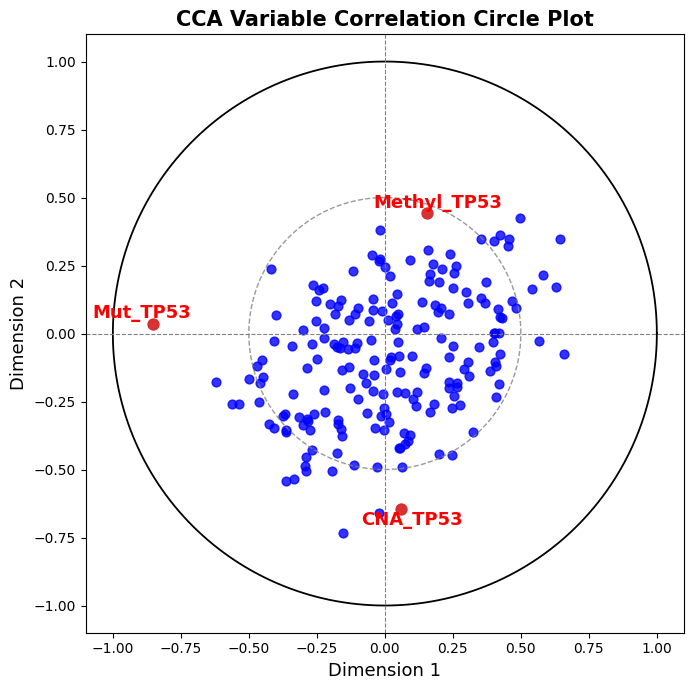

In [8]:
U = X_input.values @ np.asarray(A_full)
V = Y_input.values @ np.asarray(B)
plt_cca(U,V,X_input,Y_input,mode = "v",remove_last_xcols=4,Xnames = X_input.columns,title_v="CCA Variable Correlation Circle Plot")